# 03d Floor ramp: why does the scan floor ramp against the model's flat floor outside room B? (issue #26)

**Slice.** The whole CRAS building, not room B: the point of the question is what happens away from the room that 03a's ICP refinement used. The scan is moved into the model frame with 03a's refined frame (`outputs/03a/frame.json`, key `refined_scan_to_model_4x4`), so the ramp that 03a section 4 found is the one measured here.

**Question.** 03a section 4 found that the scan floor, 98 % floor-class points, is a smooth ramp against the model's flat floor (z = 0.100 m): +1.22 mm/m in x, -0.82 mm/m in y (0.084 degrees, falling to the north-west), -22 mm to +16 mm across the building. Why?

- **H1, a rigid frame tilt** that room B's ICP cannot see (room B is small and flat, so its refinement fixes a plane through it but not a small rotation about it). The whole scan is rotated a little against the model: floor and ceiling and walls turn together.
- **H2, drift between the merged scanner setups.** The scan is a merge of setups, each registered to the others with some error. Each setup sees its own floor, ceiling and walls, so a setup that sits a little too high or tilted moves all three together, but in patches, not as one plane.
- **H3, the floor really slopes**, and the model's does not (the model's floor is flat, 03a). The building's floor would then differ from the model, and that is a finding about the building, not about the registration.

**Evidence that does not tune anything on the gate's samples.** Nothing here feeds a verdict, a rule or a parameter (owner decision 2026-11-04: Phase 0.5 records the cause and a decision only; rule changes go to Phase 2, issue #33). Every number below is a measurement of the scan against the model's levels or against itself.

1. **Room height** (the strong test, hardly dependent on the model). In every 1 m cell where the scan has a floor sheet and a ceiling sheet, the height from floor to ceiling does not depend on the frame at all: a rigid tilt turns floor and ceiling together and leaves it unchanged. If the room height changes across the building, the floor and the ceiling are not rigid with respect to each other: that part of the ramp is not the frame.
2. **Residual correlation** (H2). After removing each surface's own plane, do the floor and ceiling of the same place stay together?
3. **Wall lean** (weak, kept anyway). A rigid tilt also leans every wall.

Terms (scan, model, element, scan class, registration residual) are defined in [CONTEXT.md](../CONTEXT.md). All randomness is seeded. Nothing is written outside `outputs/03d/` (gitignored).

**What each hypothesis predicts, written before the results.** g is a gradient (mm/m, as (x, y)); the room height is ceiling minus floor; ceiling offset is the ceiling's height minus the model's covering level.

| | floor offset g_f | ceiling offset g_c | room height g_h = g_c - g_f | floor and ceiling residuals about their own planes | wall lean (offset along the outward normal n per metre of height) |
|---|---|---|---|---|---|
| **H1** rigid frame tilt | g (the tilt) | the same g | 0 | uncorrelated (noise) | -g . n |
| **H2** setup drift | patchy, partly planar | the same patches as the floor | 0 on every patch, planar or not | correlated (the same patches in both) | no common pattern in n |
| **H3** the floor really slopes | g | 0 | -g (the room gets lower as the floor rises) | uncorrelated (noise) | 0 |

The causes can coexist, one per component (x and y may differ), and the table is read per component. A tilt of the whole *building* against the model (a real lean) is indistinguishable from H1 here: both turn floor, ceiling and walls together, so the test cannot and does not try to tell them apart.

Sections: (1) parameters and the measurement functions, (2) a known-answer check on a synthetic room (both a rotation and a sloped floor, asserted), (3) the model's levels and the scan, (4) room height, (5) the same per level and region, (6) residual correlation (H2), (7) wall lean, (8) figures and summary, then the reading, the conclusion and the decision.

## 1. Parameters and the measurement functions

In [1]:
import json, os, time
from collections import defaultdict
from dataclasses import dataclass
from pathlib import Path
from typing import Any

import ifcopenshell
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display
from matplotlib.collections import LineCollection
from scipy.spatial.transform import Rotation

os.environ["OPEN3D_DISABLE_WEB_VISUALIZER"] = "true"  # before the import (scan_vs_bim.load imports Open3D): skips its Jupyter web-visualizer banner
from scan_vs_bim.load import ElementMesh, load_ifc_elements
from scan_vs_bim.memory import peak_rss_gb
from scan_vs_bim.ramp import Gradient, block_resamples, plane_gradient

%config InlineBackend.figure_format = 'png'
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 100, "font.size": 9})

# All parameters in one place. Lengths in metres. Judgement calls and diagnostic-only values are marked (none is from a standard).
SEED = 0
CRAS = Path("../data/cras")
CACHE, IFC = CRAS / "cras_voxel_1cm.npz", CRAS / "craslabbim.ifc"
FRAME = Path("../outputs/03a/frame.json")  # 03a's refined frame (run 03a first)
OUT = Path("../outputs/03d")  # gitignored; never write outside outputs/
OUT.mkdir(parents=True, exist_ok=True)
CHUNK = 4_000_000  # points transformed at a time (the same as 03a)
CEILING, FLOOR, WALL = 1, 2, 3  # scan class ids (index in 03a's CLASS_NAMES list: ceiling, floor, wall)
CLASS_NAMES = {CEILING: "ceiling", FLOOR: "floor", WALL: "wall"}

TOL = 0.015  # USIBD LOA30: at most 15 mm at 2 sigma (the number 03a judges the slab by); only quoted here
FLOOR_BAND = 0.10  # (diagnostic only) floor-class points further than this from the model's floor are not used (03a's BAND)
CELL = 1.0  # (diagnostic only) cell size of the height test; 03a's map used 2 m
MIN_FLOOR_PTS, MIN_CEIL_PTS = 500, 300  # (diagnostic only) points a floor cell / the ceiling sheet of a cell needs
CEIL_BIN, CEIL_WINDOW, CEIL_IQR_MAX = 0.02, 0.04, 0.01  # (diagnostic only) the ceiling sheet: histogram bin, points within the window around its peak, and it counts as a thin sheet only if its IQR <= this
LEVEL_TOL = 0.05  # (diagnostic only) a ceiling sheet further than this from the level of the covering over it is dropped (and counted)
MIN_AREA = 1.0  # (diagnostic only) m2 of downward-facing covering for a covering to count as a ceiling
GROUP_MIN_CELLS = 8  # (diagnostic only) a covering with fewer cells than this is left out of the fits (its intercept would be a few cells' noise)
SUBSET_MIN_CELLS = 15  # (diagnostic only) a level, covering or region with fewer cells than this gets no row of its own in section 5
BLOCK, N_BOOT = 4.0, 2000  # (diagnostic only) the bootstrap resamples whole 4 m blocks of cells; cells next to each other are alike, so single cells would give too narrow an interval
X_SPLIT, Y_SPLIT = 0.0, 8.0  # (diagnostic only) the regions of 03a section 4 (x < 0 / x >= 0, y < 8 / y >= 8)
WALL_Z, WALL_ZBIN, WALL_ZBIN_MIN_PTS, WALL_MIN_BINS = (0.3, 2.2), 0.1, 50, 8  # (diagnostic only) wall lean: the heights used, the median per 10 cm of height, points per bin, bins per face
WALL_MIN_PTS, WALL_MIN_SPAN = 800, 1.2  # (diagnostic only) a face needs this many points over a span of this height
WALL_END_TRIM, WALL_PAD, WALL_BEHIND, WALL_AHEAD, WALL_SHEET = 0.2, 0.12, 0.05, 0.10, 0.02  # (diagnostic only) trimmed from the wall's ends; the wall's box padded; the look behind / ahead of the model face; the sheet's half width around its median offset
READMIT_NEAR = 1.0  # (diagnostic only) second sensitivity of section 4: a left-out ceiling sheet within LEVEL_TOL of the level of a covering whose plan box is within this many metres of the cell is taken back
CEILING_MIN_Z = 1.5  # (diagnostic only) ceiling-class points below this height are not kept (clutter classed as ceiling; the lowest model level is 2.30 m)
MM = 1000.0


@dataclass(frozen=True)
class Covering:
    """One model covering (a suspended ceiling, one per room): the height of its down-facing face and the plan box that face covers."""
    guid: str
    level: float
    lo: tuple[float, float]
    hi: tuple[float, float]


@dataclass
class Cells:
    """One row per cell that has both a floor sheet and a ceiling sheet. Heights in metres in the model frame."""
    x: np.ndarray  # cell centre
    y: np.ndarray
    floor: np.ndarray  # median z of the floor-class points
    ceiling: np.ndarray  # median z of the ceiling sheet
    level: np.ndarray  # the level of the covering the sheet is assigned to
    room: np.ndarray  # the index of that covering
    floor_z: float  # the model's floor level

    def subset(self, idx: np.ndarray) -> "Cells":
        return Cells(self.x[idx], self.y[idx], self.floor[idx], self.ceiling[idx], self.level[idx], self.room[idx], self.floor_z)

    def groups(self, by: str) -> np.ndarray:
        """The grouping of the fits: one intercept per ceiling `level` (the levels differ by design), or per covering (`room`: each suspended ceiling may sit a little differently as built)."""
        return self.level if by == "level" else self.room

    def floor_offset(self) -> np.ndarray:
        return self.floor - self.floor_z

    def ceiling_offset(self) -> np.ndarray:
        return self.ceiling - self.level

    def height_change(self) -> np.ndarray:
        return self.ceiling_offset() - self.floor_offset()  # the room height (ceiling - floor) minus the model's (level - floor level)


def cell_groups(x: np.ndarray, y: np.ndarray, min_points: int) -> list[np.ndarray]:
    """Indices of the points of each 1 m cell that has at least `min_points` of them."""
    key = (np.floor(x / CELL).astype(np.int64) + 10_000) * 100_000 + np.floor(y / CELL).astype(np.int64) + 10_000
    order = np.argsort(key, kind="stable")
    return [g for g in np.split(order, np.flatnonzero(np.diff(key[order])) + 1) if len(g) >= min_points]


def cell_centre(x: float, y: float) -> tuple[float, float]:
    return (float(np.floor(x / CELL)) + 0.5) * CELL, (float(np.floor(y / CELL)) + 0.5) * CELL


def floor_medians(points: np.ndarray, scan_class: np.ndarray, floor_z: float) -> dict[tuple[float, float], float]:
    """Cell centre -> median z of the floor-class points within FLOOR_BAND of floor_z, for the cells with enough of them."""
    f = points[(scan_class == FLOOR) & (np.abs(points[:, 2] - floor_z) < FLOOR_BAND)]
    return {cell_centre(f[g[0], 0], f[g[0], 1]): float(np.median(f[g, 2])) for g in cell_groups(f[:, 0], f[:, 1], MIN_FLOOR_PTS)}


def ceiling_sheet(z: np.ndarray) -> float | None:
    """The dominant thin sheet of one cell's ceiling-class heights: the points within CEIL_WINDOW of the histogram's peak, if there are enough of them and their IQR is at most CEIL_IQR_MAX. Its median z, or None."""
    counts, edges = np.histogram(z, bins=np.arange(z.min() - CEIL_BIN, z.max() + 2 * CEIL_BIN, CEIL_BIN))
    peak = edges[np.argmax(counts)] + CEIL_BIN / 2
    sheet = z[np.abs(z - peak) <= CEIL_WINDOW]
    if len(sheet) < MIN_CEIL_PTS or np.subtract(*np.percentile(sheet, [75, 25])) > CEIL_IQR_MAX:
        return None
    return float(np.median(sheet))


def cell_table(points: np.ndarray, scan_class: np.ndarray, floor_z: float, coverings: list[Covering], any_level: bool = False, readmit_near: float = 0.0,
               off_level: list[tuple[float, float, int, float]] | None = None) -> tuple[Cells, dict[str, int]]:
    """The cells with a floor sheet and a thin ceiling sheet within LEVEL_TOL of the level of a covering whose plan box holds the cell's centre (the nearest level if several do),
    and counts of what was left out. `off_level`, if given, collects the sheets left out for being too far from the level of every covering over them: (x, y, nearest covering, offset from its level).
    Two sensitivities, not the reading: `any_level=True` sends a sheet to the covering with the nearest level wherever that covering is; `readmit_near > 0` keeps the main rule but also takes a sheet
    that the rule would leave out when it lies within LEVEL_TOL of the level of a covering whose plan box is within `readmit_near` metres of the cell's centre (a ceiling that runs a little past its modelled box)."""
    floor_med = floor_medians(points, scan_class, floor_z)
    c = points[scan_class == CEILING]
    rows: list[tuple[float, float, float, float, float, int]] = []
    count = dict(floor_cells=len(floor_med), ceiling_cells=0, thin_sheet=0, no_covering=0, wrong_level=0, no_floor=0)
    for g in cell_groups(c[:, 0], c[:, 1], MIN_CEIL_PTS):
        count["ceiling_cells"] += 1
        zc = ceiling_sheet(c[g, 2])
        if zc is None:
            continue
        count["thin_sheet"] += 1
        centre = cell_centre(c[g[0], 0], c[g[0], 1])
        over = list(range(len(coverings))) if any_level else [i for i, cv in enumerate(coverings) if cv.lo[0] <= centre[0] <= cv.hi[0] and cv.lo[1] <= centre[1] <= cv.hi[1]]
        best = min(over, key=lambda i: abs(zc - coverings[i].level)) if over else None  # coverings can overlap in plan (a lowered strip inside a room): the sheet belongs to the one whose level it matches
        if (best is None or abs(zc - coverings[best].level) > LEVEL_TOL) and readmit_near > 0:
            close = [i for i, cv in enumerate(coverings) if abs(zc - cv.level) <= LEVEL_TOL
                     and np.hypot(max(cv.lo[0] - centre[0], 0, centre[0] - cv.hi[0]), max(cv.lo[1] - centre[1], 0, centre[1] - cv.hi[1])) <= readmit_near]
            if close:
                best = min(close, key=lambda i: abs(zc - coverings[i].level))
        if best is None:
            count["no_covering"] += 1
        else:
            if abs(zc - coverings[best].level) > LEVEL_TOL:
                count["wrong_level"] += 1
                if off_level is not None:
                    off_level.append((*centre, best, zc - coverings[best].level))
            elif centre not in floor_med:
                count["no_floor"] += 1
            else:
                rows.append((*centre, floor_med[centre], zc, coverings[best].level, best))
    a = np.array(rows, dtype=float).reshape(-1, 6)
    keep = np.isin(a[:, 5], [r for r in np.unique(a[:, 5]) if (a[:, 5] == r).sum() >= GROUP_MIN_CELLS])
    count["small_covering"] = int((~keep).sum())
    x, y, fz, cz, lv, room = a[keep].T
    return Cells(x, y, fz, cz, lv, room.astype(int), floor_z), count


def gradients(cells: Cells, idx: np.ndarray, by: str = "level") -> tuple[Gradient, Gradient, Gradient]:
    """Floor, ceiling and room-height gradients over the chosen cells: one intercept per group (`by`: "level" or "room"), one slope shared by all."""
    c = cells.subset(idx)
    return tuple(plane_gradient(c.x, c.y, v, c.groups(by)) for v in (c.floor_offset(), c.ceiling_offset(), c.height_change()))  # type: ignore[return-value]


def gradient_vector(cells: Cells, idx: np.ndarray, by: str = "level") -> np.ndarray:
    """(floor gx, gy, ceiling gx, gy, height gx, gy) in mm/m."""
    return np.array([[g.gx, g.gy] for g in gradients(cells, idx, by)]).ravel() * MM


def bootstrap_vectors(cells: Cells, idx: np.ndarray, by: str = "level") -> np.ndarray:
    """The gradient vector (mm/m) of N_BOOT seeded block resamples of the cells `idx`; a resample whose cells lie on a line is skipped."""
    out: list[np.ndarray] = []
    for r in block_resamples(cells.x[idx], cells.y[idx], BLOCK, N_BOOT, SEED):
        try:
            out.append(gradient_vector(cells, idx[r], by))
        except ValueError:
            pass
    return np.array(out)


def interval(values: np.ndarray) -> list[float]:
    return [float(v) for v in np.percentile(values, [2.5, 97.5])]


def fmt_interval(values: np.ndarray) -> str:
    lo, hi = interval(values)
    return f"[{lo:+.2f}, {hi:+.2f}]"


def face_leans(points: np.ndarray, scan_class: np.ndarray, walls: list[ElementMesh]) -> np.ndarray:
    """Per qualifying model wall face, a row (nx, ny, lean, n_points, cx, cy). `lean` is the slope of the scan's offset along the face's outward normal
    against height (m per m): the median offset per WALL_ZBIN of height, then a line through them. A face qualifies when its sheet has enough points over a tall enough span."""
    wp = points[(scan_class == WALL) & (points[:, 2] > WALL_Z[0]) & (points[:, 2] < WALL_Z[1])]
    rows: list[tuple[float, float, float, float, float, float]] = []
    for w in walls:
        tri = w.vertices[w.faces]
        n = np.cross(tri[:, 1] - tri[:, 0], tri[:, 2] - tri[:, 0])
        area = np.linalg.norm(n, axis=1)
        n = n / np.maximum(area, 1e-12)[:, None]
        horizontal = np.abs(n[:, 2]) < 0.01
        angle = np.arctan2(n[horizontal, 1], n[horizontal, 0]) % np.pi  # the thickness axis: the face normals' dominant direction, by area
        hist, edges = np.histogram(angle, bins=360, range=(0, np.pi), weights=area[horizontal])
        theta = (edges[np.argmax(hist)] + edges[np.argmax(hist) + 1]) / 2
        near = np.abs(angle - theta) < np.pi / 360  # the bin is 0.5 degrees wide: refine its centre to the faces' own mean angle (a 0.25 degree error in the axis would read as 4 mm/m along the wall)
        theta = float(np.average(angle[near], weights=area[horizontal][near]))
        axis, along = np.array([np.cos(theta), np.sin(theta)]), np.array([-np.sin(theta), np.cos(theta)])
        s0, u0 = w.vertices[:, :2] @ axis, w.vertices[:, :2] @ along
        lo, hi = w.vertices.min(0)[:2] - WALL_PAD, w.vertices.max(0)[:2] + WALL_PAD
        q = wp[((wp[:, :2] >= lo) & (wp[:, :2] <= hi)).all(1)]
        if len(q) < WALL_MIN_PTS:
            continue
        s, u = q[:, :2] @ axis, q[:, :2] @ along
        inner = (u > u0.min() + WALL_END_TRIM) & (u < u0.max() - WALL_END_TRIM)
        for face, sign in ((s0.min(), -1), (s0.max(), 1)):
            d = (s - face) * sign  # offset along the outward normal
            m = inner & (d > -WALL_BEHIND) & (d < WALL_AHEAD)
            if m.sum() < WALL_MIN_PTS:
                continue
            m &= np.abs(d - np.median(d[m])) < WALL_SHEET
            if m.sum() < WALL_MIN_PTS or np.ptp(q[m, 2]) < WALL_MIN_SPAN:
                continue
            z, off = q[m, 2], d[m]
            bins = np.arange(WALL_Z[0], WALL_Z[1] + 1e-9, WALL_ZBIN)
            which = np.digitize(z, bins)
            zs: list[float] = []
            ds: list[float] = []
            for b in range(1, len(bins)):
                k = which == b
                if k.sum() >= WALL_ZBIN_MIN_PTS:
                    zs.append(np.median(z[k]))
                    ds.append(np.median(off[k]))
            if len(zs) < WALL_MIN_BINS:
                continue
            normal = axis * sign
            centre = q[m, :2].mean(0)
            rows.append((normal[0], normal[1], np.polyfit(zs, ds, 1)[0], float(m.sum()), centre[0], centre[1]))
    return np.array(rows, dtype=float).reshape(-1, 6)


def lean_fit(leans: np.ndarray) -> np.ndarray:
    """lean = a * nx + b * ny through the faces: (a, b) in m per m."""
    return np.linalg.lstsq(leans[:, :2], leans[:, 2], rcond=None)[0]


def footprints(walls: list[ElementMesh]) -> list[np.ndarray]:
    """Plan outline of each wall: the boundary edges of its bottom triangles (only for drawing the maps)."""
    segments: list[np.ndarray] = []
    for w in walls:
        tri = w.vertices[w.faces]
        bottom = np.all(np.abs(tri[:, :, 2] - w.vertices[:, 2].min()) < 1e-6, axis=1)
        edges: dict[tuple[tuple[float, float], tuple[float, float]], int] = defaultdict(int)
        for t in tri[bottom]:
            for i in range(3):
                a, b = tuple(np.round(t[i, :2], 4)), tuple(np.round(t[(i + 1) % 3, :2], 4))
                edges[(a, b) if a <= b else (b, a)] += 1  # type: ignore[index]
        segments += [np.array(e) for e, k in edges.items() if k == 1]
    return segments


print(f"functions defined; peak RSS {peak_rss_gb():.2f} GB")

functions defined; peak RSS 0.16 GB


## 2. Known answer: a synthetic room rotated by a known small rotation, and the same room with only its floor sloped

A room of 10 m by 10 m: a flat floor (z = 0.100), a flat ceiling at two levels (2.30 for x < 0, 2.64 for x >= 0), four plumb 10 cm walls. The scan is the room's surfaces sampled at 3 cm with 1 mm of noise; the model is the same room without the noise or the turn. Two cases, run through exactly the functions used on the real data below:

1. **Rigid tilt:** the scan is rotated about the origin by the small rotation whose floor gradient is g = (+1.2, -0.8) mm/m (about x by +g_y and about y by -g_x: z' = z + w_x y - w_y x to first order). A rigid turn leaves the room height alone, so **g_f == g_c == g, the height gradient is 0, and the lean of a wall face with outward normal n is -g . n**. (A plumb face point at height z moves along n by n . (w x p) = z (w_y n_x - w_x n_y) = -z g . n.)
2. **Floor-only slope:** only the floor is tilted by the same g. **g_f == g, g_c == 0, the height gradient is -g, and no wall leans.**

In [2]:
SYN_FLOOR_Z = 0.100


def box_mesh(x0: float, x1: float, y0: float, y1: float, z0: float, z1: float, guid: str) -> ElementMesh:
    v = np.array([[x, y, z] for x in (x0, x1) for y in (y0, y1) for z in (z0, z1)], dtype=float)
    f = np.array([[0, 1, 3], [0, 3, 2], [4, 6, 7], [4, 7, 5], [0, 4, 5], [0, 5, 1], [2, 3, 7], [2, 7, 6], [0, 2, 6], [0, 6, 4], [1, 5, 7], [1, 7, 3]], dtype=np.int32)
    return ElementMesh(guid, "IfcWallStandardCase", v, f)


def synthetic_room(g: tuple[float, float], rigid: bool) -> tuple[np.ndarray, np.ndarray, list[ElementMesh], list[Covering]]:
    """Scan points, their classes, the model's walls and the model's two coverings. `g` is the floor gradient (m/m): the whole room rotated rigidly, or only the floor sloped."""
    rng = np.random.default_rng(SEED)
    step = 0.03
    gx_, gy_ = np.meshgrid(np.arange(-5 + step / 2, 5, step), np.arange(step / 2, 10, step))
    xs, ys = gx_.ravel(), gy_.ravel()
    floor = np.column_stack([xs, ys, SYN_FLOOR_Z + rng.normal(0, 0.001, len(xs))])
    ceiling = np.column_stack([xs, ys, np.where(xs < 0, 2.30, 2.64) + rng.normal(0, 0.001, len(xs))])
    walls_model = [box_mesh(-5, 5, -0.1, 0, 0, 3, "a"), box_mesh(-5, 5, 10, 10.1, 0, 3, "b"), box_mesh(-5.1, -5, -0.1, 10.1, 0, 3, "c"), box_mesh(5, 5.1, -0.1, 10.1, 0, 3, "d")]
    wall_pts: list[np.ndarray] = []
    zs = np.arange(0.3, 2.2, step)
    for w in walls_model:
        lo, hi = w.vertices.min(0), w.vertices.max(0)
        along_x = (hi[0] - lo[0]) > (hi[1] - lo[1])
        along = np.arange(lo[0] if along_x else lo[1], hi[0] if along_x else hi[1], step)
        for face in (lo[1], hi[1]) if along_x else (lo[0], hi[0]):
            a, z = np.meshgrid(along, zs)
            a, z = a.ravel(), z.ravel()
            wall_pts.append(np.column_stack([a, np.full(len(a), face), z]) if along_x else np.column_stack([np.full(len(a), face), a, z]))
    walls_scan = np.concatenate(wall_pts)
    if rigid:
        rot = Rotation.from_rotvec([g[1], -g[0], 0.0])  # w_x = g_y, w_y = -g_x
        parts = [rot.apply(p) for p in (floor, ceiling, walls_scan)]
    else:
        parts = [floor + np.column_stack([np.zeros(len(xs)), np.zeros(len(xs)), g[0] * xs + g[1] * ys]), ceiling, walls_scan]
    return np.concatenate(parts), np.concatenate([np.full(len(p), k) for p, k in zip(parts, (FLOOR, CEILING, WALL))]), walls_model, [Covering("w", 2.30, (-5, 0), (0, 10)), Covering("e", 2.64, (0, 0), (5, 10))]


G_KNOWN = (+0.0012, -0.0008)
for case, rigid in (("rigid tilt", True), ("floor-only slope", False)):
    syn_pts, syn_cls, syn_walls, syn_coverings = synthetic_room(G_KNOWN, rigid)
    syn_cells, syn_left_out = cell_table(syn_pts, syn_cls, SYN_FLOOR_Z, syn_coverings)
    assert len(syn_cells.x) == 100 and sum(syn_left_out[k] for k in ("no_covering", "wrong_level", "no_floor", "small_covering")) == 0, syn_left_out  # every 1 m cell of the 10 x 10 room
    gf, gc, gh = gradients(syn_cells, np.arange(len(syn_cells.x)))
    syn_leans = face_leans(syn_pts, syn_cls, syn_walls)
    a, b = lean_fit(syn_leans)
    print(f"{case}: floor ({gf.gx * MM:+.3f}, {gf.gy * MM:+.3f}), ceiling ({gc.gx * MM:+.3f}, {gc.gy * MM:+.3f}), height ({gh.gx * MM:+.3f}, {gh.gy * MM:+.3f}) mm/m;"
          f" {len(syn_leans)} wall faces, lean = {a * MM:+.3f} nx {b * MM:+.3f} ny mm/m")
    tol = 0.01 / MM  # 0.01 mm/m, far below the effects measured below
    assert np.allclose([gf.gx, gf.gy], G_KNOWN, atol=tol) and len(syn_leans) == 8
    if rigid:
        assert np.allclose([gc.gx, gc.gy], G_KNOWN, atol=tol) and np.allclose([gh.gx, gh.gy], 0, atol=tol)
        assert np.allclose(syn_leans[:, 2], -(syn_leans[:, 0] * G_KNOWN[0] + syn_leans[:, 1] * G_KNOWN[1]), atol=tol)  # lean = -g . n, face by face
        assert np.allclose([a, b], [-G_KNOWN[0], -G_KNOWN[1]], atol=tol)
    else:
        assert np.allclose([gc.gx, gc.gy], 0, atol=tol) and np.allclose([gh.gx, gh.gy], [-G_KNOWN[0], -G_KNOWN[1]], atol=tol)
        assert np.allclose(syn_leans[:, 2], 0, atol=tol)
print("known answers hold: a rigid tilt gives floor == ceiling, height 0 and lean -g.n; a sloped floor gives ceiling 0, height -g_f and no lean")
del syn_pts, syn_cls, syn_cells, syn_walls

rigid tilt: floor (+1.199, -0.801), ceiling (+1.198, -0.802), height (-0.001, -0.001) mm/m; 8 wall faces, lean = -1.200 nx +0.800 ny mm/m


floor-only slope: floor (+1.199, -0.801), ceiling (-0.001, -0.001), height (-1.200, +0.800) mm/m; 8 wall faces, lean = +0.000 nx -0.000 ny mm/m
known answers hold: a rigid tilt gives floor == ceiling, height 0 and lean -g.n; a sloped floor gives ceiling 0, height -g_f and no lean


## 3. The model's levels, and the scan in the model frame

The floor level is the main slab's upward-facing area (03a: all of it at z = 0.100 m). The ceiling levels are the heights of the covering triangles that face down, by area. The scan is moved with 03a's refined frame, in chunks, and only the points the tests use are kept: floor-class points within `FLOOR_BAND` of the floor, ceiling-class points above 1.5 m, wall-class points within `WALL_Z`.

In [3]:
t0 = time.time()
model = ifcopenshell.open(str(IFC))
wanted = [e.GlobalId for c in ("IfcSlab", "IfcCovering", "IfcWallStandardCase") for e in model.by_type(c)]
elements = load_ifc_elements(IFC, only_guids=wanted)
del model
slabs = [e for e in elements if e.ifc_class == "IfcSlab"]
coverings = [e for e in elements if e.ifc_class == "IfcCovering"]
walls = [e for e in elements if e.ifc_class == "IfcWallStandardCase"]


def facing_area(el: ElementMesh, up: bool) -> dict[float, float]:
    """Area of the element's horizontal triangles that face up (or down), by height rounded to 1 cm."""
    tri = el.vertices[el.faces]
    n = np.cross(tri[:, 1] - tri[:, 0], tri[:, 2] - tri[:, 0])
    a = np.linalg.norm(n, axis=1)
    pick = n[:, 2] > 0.99 * a if up else n[:, 2] < -0.99 * a
    out: dict[float, float] = defaultdict(float)
    for z, area in zip(np.round(tri[pick].mean(1)[:, 2], 2), a[pick] / 2):
        out[float(z)] += float(area)
    return out


slab_levels = {s.global_id: facing_area(s, up=True) for s in slabs}
main_slab = max(slab_levels, key=lambda g: sum(slab_levels[g].values()))
FLOOR_Z = max(slab_levels[main_slab], key=lambda z: slab_levels[main_slab][z])


def covering_of(el: ElementMesh) -> Covering | None:
    """The covering's main down-facing height (by area) and the plan box of the down-facing triangles at that height; None if its down-facing area is under MIN_AREA."""
    area = facing_area(el, up=False)
    if not area or max(area.values()) < MIN_AREA:
        return None
    level = max(area, key=lambda z: area[z])
    tri = el.vertices[el.faces]
    n = np.cross(tri[:, 1] - tri[:, 0], tri[:, 2] - tri[:, 0])
    down = (n[:, 2] < -0.99 * np.linalg.norm(n, axis=1)) & (np.abs(tri.mean(1)[:, 2] - level) < 0.01)
    xy = tri[down][:, :, :2].reshape(-1, 2)
    return Covering(el.global_id, level, (float(xy[:, 0].min()), float(xy[:, 1].min())), (float(xy[:, 0].max()), float(xy[:, 1].max())))


COVERINGS = [cv for cv in map(covering_of, coverings) if cv is not None]
LEVELS = np.array(sorted({cv.level for cv in COVERINGS}))
print(f"{len(elements)} model elements ({len(slabs)} slabs, {len(coverings)} coverings, {len(walls)} walls) in {time.time() - t0:.0f} s")
print(f"floor level: slab {main_slab}, {sum(slab_levels[main_slab].values()):.0f} m2 upward-facing, {slab_levels[main_slab][FLOOR_Z]:.0f} m2 of it at z = {FLOOR_Z:.2f} m")
print(f"{len(COVERINGS)} coverings (one per room) at {len(LEVELS)} ceiling levels: plan box and height of the down-facing face")
for cv in sorted(COVERINGS, key=lambda c: (c.level, c.lo)):
    print(f"  {cv.guid}  level {cv.level:.2f} m  x {cv.lo[0]:+5.1f} to {cv.hi[0]:+5.1f}, y {cv.lo[1]:+5.1f} to {cv.hi[1]:+5.1f}")
overlaps = [(a.guid, b.guid) for i, a in enumerate(COVERINGS) for b in COVERINGS[i + 1:] if a.lo[0] < b.hi[0] and b.lo[0] < a.hi[0] and a.lo[1] < b.hi[1] and b.lo[1] < a.hi[1]]
print(f"pairs of coverings whose plan boxes overlap: {len(overlaps)} (a ceiling sheet in an overlap goes to the covering whose level is nearest)")
assert abs(FLOOR_Z - 0.100) < 1e-6  # 03a section 4: the model's floor is flat at 0.100

T = np.array(json.loads(FRAME.read_text())["refined_scan_to_model_4x4"])
cache = np.load(CACHE)
xyz, scan_cls = cache["xyz"], cache["cls"]
kept: list[np.ndarray] = []
kept_cls: list[np.ndarray] = []
for lo in range(0, len(xyz), CHUNK):
    q = xyz[lo:lo + CHUNK].astype(np.float64) @ T[:3, :3].T + T[:3, 3]
    k = scan_cls[lo:lo + CHUNK]
    m = (((k == FLOOR) & (np.abs(q[:, 2] - FLOOR_Z) < FLOOR_BAND)) | ((k == CEILING) & (q[:, 2] > CEILING_MIN_Z))
         | ((k == WALL) & (q[:, 2] > WALL_Z[0]) & (q[:, 2] < WALL_Z[1])))
    kept.append(q[m])
    kept_cls.append(k[m])
n_cache = len(xyz)
del xyz, scan_cls, cache
P, C = np.concatenate(kept), np.concatenate(kept_cls)
del kept, kept_cls
print(f"scan cache {n_cache:,} points; kept {len(P):,}: " + ", ".join(f"{CLASS_NAMES[k]} {int((C == k).sum()):,}" for k in (FLOOR, CEILING, WALL)) + f"; peak RSS {peak_rss_gb():.2f} GB, {time.time() - t0:.0f} s")

73 model elements (5 slabs, 7 coverings, 61 walls) in 10 s
floor level: slab 3XP_HdJcfD9xJPuaOu_0Jb, 386 m2 upward-facing, 386 m2 of it at z = 0.10 m
7 coverings (one per room) at 4 ceiling levels: plan box and height of the down-facing face
  119XF8U0bC_wlCogT_CGPr  level 2.30 m  x  -1.8 to  +0.2, y  -4.3 to +13.8
  33gtcvddH7cec8$WOT4fKs  level 2.30 m  x  +0.6 to  +2.1, y +11.0 to +19.8
  2unE$VYSL2OPIL$6LYYd$b  level 2.64 m  x  -2.7 to  +1.1, y  -4.3 to +13.8
  2unE$VYSL2OPIL$6LYYccT  level 2.80 m  x  +0.5 to  +8.0, y  +3.0 to +10.9
  2unE$VYSL2OPIL$6LYYcpM  level 2.80 m  x  +0.6 to  +8.0, y +11.0 to +19.8
  2unE$VYSL2OPIL$6LYYdVk  level 2.80 m  x  +1.2 to  +8.0, y  -4.2 to  +2.9
  2lFZpwIy99qQvqCd3wc5iU  level 2.93 m  x  -9.6 to  -2.1, y  -0.8 to +19.8
pairs of coverings whose plan boxes overlap: 6 (a ceiling sheet in an overlap goes to the covering whose level is nearest)


scan cache 20,404,814 points; kept 9,821,336: floor 2,810,061, ceiling 4,866,625, wall 2,144,650; peak RSS 0.38 GB, 21 s


## 4. Room height: floor, ceiling and room height across the building

One row per 1 m cell with a floor sheet (median z of the floor-class points near the floor level) **and** a thin ceiling sheet (the histogram peak of the ceiling-class points, IQR <= 1 cm) within 5 cm of the level of the model covering over the cell. Per cell, the floor offset is floor z - 0.100, the ceiling offset is ceiling z - the covering's level, and the room height change is the ceiling offset minus the floor offset. Each is fitted with one plane and one (gx, gy) shared by all cells. The intercept is the part that needs a decision, and it is shown both ways:

- **one intercept per ceiling level** (the first, as planned): the levels differ by design, the coverings at one level are assumed to sit at the same height as built;
- **one intercept per covering** (a room's suspended ceiling): each covering may sit a little higher or lower than the model has it. The model's coverings are one per room, so this grouping is fixed by the model, not by looking at the results; it is the second, stricter reading, and it is the one that does not let a step between two rooms pass as a gradient.

The intervals are 95 % intervals from a seeded block bootstrap that resamples whole 4 m blocks of cells.

In [4]:
off_sheets: list[tuple[float, float, int, float]] = []
cells, left_out = cell_table(P, C, FLOOR_Z, COVERINGS, off_level=off_sheets)
n_cells = len(cells.x)
ALL = np.arange(n_cells)
print(f"floor cells (>= {MIN_FLOOR_PTS} points near the floor): {left_out['floor_cells']}; ceiling cells (>= {MIN_CEIL_PTS} points): {left_out['ceiling_cells']}")
print(f"ceiling cells with a thin sheet (IQR <= {CEIL_IQR_MAX * MM:.0f} mm): {left_out['thin_sheet']}; of these left out: {left_out['no_covering']} under no covering, {left_out['wrong_level']} further than {LEVEL_TOL * MM:.0f} mm from the level of the covering over them, "
      f"{left_out['no_floor']} without a floor sheet, {left_out['small_covering']} under a covering with fewer than {GROUP_MIN_CELLS} cells")
print(f"cells used: {n_cells}; per ceiling level: " + ", ".join(f"{lv:.2f} m: {int((cells.level == lv).sum())}" for lv in np.unique(cells.level)) + f"; coverings with cells: {len(np.unique(cells.room))}")
print("offsets (mm), p5 / p50 / p95: " + "; ".join(f"{name} {', '.join(f'{v:+.1f}' for v in np.percentile(vals * MM, [5, 50, 95]))}" for name, vals in
      (("floor", cells.floor_offset()), ("ceiling", cells.ceiling_offset()), ("height change", cells.height_change()))))

BY = {"level": "one intercept per ceiling level", "room": "one intercept per covering"}
fits: dict[str, tuple[Gradient, Gradient, Gradient]] = {}
boots: dict[str, np.ndarray] = {}
for by, label in BY.items():
    fits[by], boots[by] = gradients(cells, ALL, by), bootstrap_vectors(cells, ALL, by)
    print(f"\n{label}: block bootstrap, {len(boots[by])} of {N_BOOT} resamples used ({BLOCK:.0f} m blocks)")
    print(f"{'':14s} {'gx mm/m':>8s} {'95 % interval':>17s} {'gy mm/m':>8s} {'95 % interval':>17s} {'rms mm':>7s}")
    for i, (name, fit) in enumerate(zip(("floor", "ceiling", "room height"), fits[by])):
        print(f"{name:14s} {fit.gx * MM:+8.2f} {fmt_interval(boots[by][:, 2 * i]):>17s} {fit.gy * MM:+8.2f} {fmt_interval(boots[by][:, 2 * i + 1]):>17s} {fit.rms * MM:7.2f}")
fl, ce, he = fits["level"]
fl_r, ce_r, he_r = fits["room"]
print(f"\n03a's floor gradient, over its 2 m cells of counted points, was (+1.22, -0.82) mm/m; over these {n_cells} cells it is ({fl.gx * MM:+.2f}, {fl.gy * MM:+.2f})")
floor_cells = floor_medians(P, C, FLOOR_Z)
fall = plane_gradient(*np.array(list(floor_cells)).T, np.array(list(floor_cells.values())) - FLOOR_Z)
print(f"over all {len(floor_cells)} floor cells, whether or not they have a ceiling sheet: ({fall.gx * MM:+.2f}, {fall.gy * MM:+.2f}) mm/m, rms {fall.rms * MM:.2f} mm")

# Robustness: a few cells sit far off every plane (near walls and room edges); leave out the cells whose floor or ceiling residual is above TOL and refit
for by, label in BY.items():
    f0, c0, _ = fits[by]
    ok = np.flatnonzero((np.abs(f0.residuals) <= TOL) & (np.abs(c0.residuals) <= TOL))
    fo, co, ho = gradients(cells, ok, by)
    print(f"leaving out the {n_cells - len(ok)} cells with a residual above {TOL * MM:.0f} mm ({label}): floor ({fo.gx * MM:+.2f}, {fo.gy * MM:+.2f}), ceiling ({co.gx * MM:+.2f}, {co.gy * MM:+.2f}), room height ({ho.gx * MM:+.2f}, {ho.gy * MM:+.2f}) mm/m")
print(f"\nthe part of the floor ramp that the ceiling shares (tilt-like) is the ceiling's gradient ({ce.gx * MM:+.2f}, {ce.gy * MM:+.2f}) per level, ({ce_r.gx * MM:+.2f}, {ce_r.gy * MM:+.2f}) per covering; "
      f"the part only the floor has (the room height changes) is minus the height gradient ({-he.gx * MM:+.2f}, {-he.gy * MM:+.2f}) per level, ({-he_r.gx * MM:+.2f}, {-he_r.gy * MM:+.2f}) per covering")
print(f"across the building (18 m in x, 24 m in y), the room height gradient adds up to {18 * he.gx * MM:+.0f}, {24 * he.gy * MM:+.0f} mm per level and {18 * he_r.gx * MM:+.0f}, {24 * he_r.gy * MM:+.0f} mm per covering (gradient times extent)")

# Sensitivity on the cells left out for being too far from their covering's level (NOT the reading; see the Reading for why the covering-over-the-cell rule is the right one)
off = np.array(off_sheets).reshape(-1, 4)
print(f"\nthe {len(off)} thin ceiling sheets further than {LEVEL_TOL * MM:.0f} mm from the level of every covering over them, by the nearest covering (offset of the sheet from that covering's level, mm, p5 / p50 / p95):")
off_summary: dict[str, dict[str, Any]] = {}
for r in np.unique(off[:, 2]).astype(int):
    cv, m = COVERINGS[r], off[:, 2] == r
    q = np.percentile(off[m, 3] * MM, [5, 50, 95])
    label = f"covering x {cv.lo[0]:+.0f}..{cv.hi[0]:+.0f} y {cv.lo[1]:+.0f}..{cv.hi[1]:+.0f} (level {cv.level:.2f} m)"
    print(f"  {label:58s} {int(m.sum()):3d} sheets, offset {q[0]:+6.0f} / {q[1]:+6.0f} / {q[2]:+6.0f}; x {off[m, 0].min():+.0f}..{off[m, 0].max():+.0f}, y {off[m, 1].min():+.0f}..{off[m, 1].max():+.0f}")
    off_summary[label] = {"n_sheets": int(m.sum()), "offset_mm_p5_p50_p95": [float(v) for v in q]}
def sensitivity_table(c: Cells) -> dict[str, Any]:
    """The three gradients (mm/m) with block bootstrap intervals over all of the cells `c`, printed and returned for summary.json."""
    idx = np.arange(len(c.x))
    b = bootstrap_vectors(c, idx)
    out: dict[str, Any] = {"n_cells": len(idx)}
    for i, (name, fit) in enumerate(zip(("floor", "ceiling", "room height"), gradients(c, idx))):
        print(f"  {name:14s} gx {fit.gx * MM:+5.2f} {fmt_interval(b[:, 2 * i]):>17s}  gy {fit.gy * MM:+5.2f} {fmt_interval(b[:, 2 * i + 1]):>17s}")
        out[name] = {"gx": fit.gx * MM, "gy": fit.gy * MM, "gx_ci": interval(b[:, 2 * i]), "gy_ci": interval(b[:, 2 * i + 1])}
    return out


cells_any, left_any = cell_table(P, C, FLOOR_Z, COVERINGS, any_level=True)
print(f"SENSITIVITY, not the reading: each sheet assigned to the nearest model level of any covering, wherever it is ({len(cells_any.x)} cells; {left_any['wrong_level']} still further than {LEVEL_TOL * MM:.0f} mm from every level):")
sensitivity = sensitivity_table(cells_any)

cells_near, left_near = cell_table(P, C, FLOOR_Z, COVERINGS, readmit_near=READMIT_NEAR)
main_cells = set(zip(cells.x, cells.y))
back = [(x, y, lv) for x, y, lv in zip(cells_near.x, cells_near.y, cells_near.level) if (x, y) not in main_cells]
print(f"SECOND SENSITIVITY, not the reading: the main rule, and also the sheets within {LEVEL_TOL * MM:.0f} mm of the level of a covering whose plan box is within {READMIT_NEAR:.0f} m of the cell: "
      f"{len(back)} cells come back ({', '.join(f'{int(n)} at {lv:.2f} m' for lv, n in zip(*np.unique([b[2] for b in back], return_counts=True)))}; x {min(b[0] for b in back):+.0f}..{max(b[0] for b in back):+.0f}), {len(cells_near.x)} cells:")
sensitivity_near = {**sensitivity_table(cells_near), "n_readmitted": len(back), "readmitted_levels": sorted({float(b[2]) for b in back}), "readmit_near_m": READMIT_NEAR}

height_ci = [interval(boots["level"][:, 4]), interval(boots["level"][:, 5])]
height_predictions = {"H1 rigid tilt (height gradient 0)": (0.0, 0.0), "H3 floor-only slope (height gradient = minus the floor's)": (-fl.gx * MM, -fl.gy * MM)}
height_inside: dict[str, list[bool]] = {}
print("\nthe room height gradient against what each hypothesis predicts (95 % intervals, one intercept per ceiling level):")
for label, pred in height_predictions.items():
    height_inside[label] = [bool(lo <= p <= hi) for p, (lo, hi) in zip(pred, height_ci)]
    print(f"  {label:58s} predicts ({pred[0]:+.2f}, {pred[1]:+.2f}): x {'inside' if height_inside[label][0] else 'OUTSIDE'}, y {'inside' if height_inside[label][1] else 'OUTSIDE'} the interval of the measured ({he.gx * MM:+.2f}, {he.gy * MM:+.2f})")

floor cells (>= 500 points near the floor): 325; ceiling cells (>= 300 points): 400
ceiling cells with a thin sheet (IQR <= 10 mm): 392; of these left out: 14 under no covering, 46 further than 50 mm from the level of the covering over them, 50 without a floor sheet, 0 under a covering with fewer than 8 cells
cells used: 282; per ceiling level: 2.30 m: 42, 2.80 m: 141, 2.93 m: 99; coverings with cells: 6
offsets (mm), p5 / p50 / p95: floor -17.6, -2.3, +11.4; ceiling -23.0, -7.8, +8.4; height change -13.8, -5.2, +7.2



one intercept per ceiling level: block bootstrap, 2000 of 2000 resamples used (4 m blocks)
                gx mm/m     95 % interval  gy mm/m     95 % interval  rms mm
floor             +1.21    [+0.61, +1.85]    -0.82    [-1.00, -0.58]    4.03
ceiling           +1.15    [+0.68, +1.68]    -1.28    [-1.43, -1.12]    3.38
room height       -0.06    [-0.83, +0.77]    -0.46    [-0.75, -0.20]    5.00



one intercept per covering: block bootstrap, 2000 of 2000 resamples used (4 m blocks)
                gx mm/m     95 % interval  gy mm/m     95 % interval  rms mm
floor             +1.11    [+0.40, +1.83]    -0.84    [-1.13, -0.61]    3.90
ceiling           +0.90    [+0.51, +1.41]    -1.40    [-1.57, -1.18]    2.83
room height       -0.21    [-1.01, +0.67]    -0.55    [-0.84, -0.19]    4.60

03a's floor gradient, over its 2 m cells of counted points, was (+1.22, -0.82) mm/m; over these 282 cells it is (+1.21, -0.82)


over all 325 floor cells, whether or not they have a ceiling sheet: (+1.40, -0.75) mm/m, rms 4.89 mm
leaving out the 2 cells with a residual above 15 mm (one intercept per ceiling level): floor (+1.04, -0.86), ceiling (+1.15, -1.28), room height (+0.11, -0.42) mm/m
leaving out the 2 cells with a residual above 15 mm (one intercept per covering): floor (+0.87, -0.97), ceiling (+0.89, -1.40), room height (+0.03, -0.43) mm/m

the part of the floor ramp that the ceiling shares (tilt-like) is the ceiling's gradient (+1.15, -1.28) per level, (+0.90, -1.40) per covering; the part only the floor has (the room height changes) is minus the height gradient (+0.06, +0.46) per level, (+0.21, +0.55) per covering
across the building (18 m in x, 24 m in y), the room height gradient adds up to -1, -11 mm per level and -4, -13 mm per covering (gradient times extent)

the 46 thin ceiling sheets further than 50 mm from the level of every covering over them, by the nearest covering (offset of the sheet fro

SENSITIVITY, not the reading: each sheet assigned to the nearest model level of any covering, wherever it is (303 cells; 8 still further than 50 mm from every level):


  floor          gx +1.77    [+0.87, +2.78]  gy -0.79    [-0.97, -0.59]
  ceiling        gx +0.28    [-0.58, +1.34]  gy -1.23    [-1.41, -1.08]
  room height    gx -1.49    [-3.16, +0.20]  gy -0.44    [-0.71, -0.21]


SECOND SENSITIVITY, not the reading: the main rule, and also the sheets within 50 mm of the level of a covering whose plan box is within 1 m of the cell: 19 cells come back (17 at 2.30 m, 2 at 2.80 m; x -2..+6), 301 cells:


  floor          gx +1.23    [+0.67, +1.85]  gy -0.81    [-0.99, -0.59]
  ceiling        gx +1.10    [+0.59, +1.72]  gy -1.24    [-1.39, -1.08]
  room height    gx -0.13    [-0.89, +0.66]  gy -0.43    [-0.69, -0.19]

the room height gradient against what each hypothesis predicts (95 % intervals, one intercept per ceiling level):
  H1 rigid tilt (height gradient 0)                          predicts (+0.00, +0.00): x inside, y OUTSIDE the interval of the measured (-0.06, -0.46)
  H3 floor-only slope (height gradient = minus the floor's)  predicts (-1.21, +0.82): x OUTSIDE, y OUTSIDE the interval of the measured (-0.06, -0.46)


## 5. The same, per ceiling level, per covering and per region

One rigid tilt has one gradient everywhere, so the gradients should agree between levels and regions. The rows are descriptive: each is a fit of its own cells, with its own block bootstrap interval in brackets; a row needs at least `SUBSET_MIN_CELLS` cells. A covering is a single group, so its row has one intercept (the room's own height) and the slope inside the room alone. The regions are fitted both ways.

In [5]:
def describe(label: str, idx: np.ndarray, by: str) -> dict[str, Any] | None:
    if len(idx) < SUBSET_MIN_CELLS:
        return None
    try:
        v, b = gradient_vector(cells, idx, by), bootstrap_vectors(cells, idx, by)
    except ValueError:
        return None
    cols = "  ".join(f"{name} {v[2 * i]:+5.2f} {fmt_interval(b[:, 2 * i]):>16s}, {v[2 * i + 1]:+5.2f} {fmt_interval(b[:, 2 * i + 1]):>16s}" for i, name in enumerate(("floor", "ceiling", "height")))
    print(f"{label:30s} {len(idx):4d} cells  {cols}")
    return {"n_cells": len(idx), "gradient_mm_per_m": [float(u) for u in v], "intervals": [interval(b[:, j]) for j in range(6)]}


print("gradients mm/m, each: gx [interval], gy [interval]")
subsets: dict[str, dict[str, Any]] = {}


def add(label: str, idx: np.ndarray, by: str) -> None:
    row = describe(label, idx, by)
    if row is not None:
        subsets[label] = row


for lv in np.unique(cells.level):
    add(f"level {lv:.2f} m", np.flatnonzero(cells.level == lv), "level")
print()
for r in np.unique(cells.room):
    cv = COVERINGS[r]
    add(f"covering x {cv.lo[0]:+.0f}..{cv.hi[0]:+.0f} y {cv.lo[1]:+.0f}..{cv.hi[1]:+.0f}", np.flatnonzero(cells.room == r), "level")
for by in BY:
    print(f"\nregions, {BY[by]}")
    for label, mask in (("x < 0", cells.x < X_SPLIT), ("x >= 0", cells.x >= X_SPLIT), ("y < 8", cells.y < Y_SPLIT), ("y >= 8", cells.y >= Y_SPLIT)):
        add(f"{label} ({by})", np.flatnonzero(mask), by)

gradients mm/m, each: gx [interval], gy [interval]


level 2.30 m                     42 cells  floor +2.45   [+0.94, +4.65], -0.85   [-1.63, -0.59]  ceiling +2.51   [+0.56, +3.09], -0.77   [-0.92, -0.19]  height +0.06   [-3.44, +1.57], +0.09   [-0.33, +1.32]


level 2.80 m                    141 cells  floor +1.09   [+0.19, +1.85], -0.86   [-1.15, -0.44]  ceiling +0.43   [+0.01, +0.91], -1.26   [-1.32, -1.14]  height -0.67   [-1.53, +0.41], -0.41   [-0.80, -0.05]


level 2.93 m                     99 cells  floor +1.27   [+0.11, +3.14], -0.78   [-1.17, -0.46]  ceiling +1.35   [+0.99, +1.75], -1.58   [-1.74, -1.43]  height +0.08   [-1.63, +1.33], -0.80   [-1.07, -0.37]



covering x +1..+8 y -4..+3       46 cells  floor +1.80   [+1.00, +2.54], -0.10   [-0.61, +0.56]  ceiling +0.40   [-1.02, +1.03], -1.03   [-1.24, -0.90]  height -1.40   [-3.25, -0.22], -0.93   [-1.70, -0.31]


covering x +1..+8 y +11..+20     49 cells  floor +0.63   [+0.30, +1.37], -2.31   [-2.45, -1.54]  ceiling +0.23   [-0.58, +0.57], -1.51   [-1.87, -1.38]  height -0.39   [-1.99, +0.22], +0.81   [-0.25, +1.04]


... (7 outputs left out)

x < 0 (room)                    132 cells  floor +1.28   [+0.22, +2.95], -0.78   [-1.10, -0.50]  ceiling +1.49   [+0.98, +2.02], -1.43   [-1.63, -1.20]  height +0.21   [-1.49, +1.45], -0.65   [-0.98, -0.22]


x >= 0 (room)                   150 cells  floor +1.05   [+0.23, +1.78], -1.12   [-1.88, -0.08]  ceiling +0.46   [+0.08, +0.87], -0.92   [-1.24, -0.52]  height -0.60   [-1.34, +0.21], +0.20   [-0.57, +0.72]


y < 8 (room)                    130 cells  floor +1.90   [+0.78, +4.00], -0.46   [-0.95, -0.07]  ceiling +0.79   [+0.25, +1.51], -1.38   [-1.98, -0.97]  height -1.12   [-2.96, +0.31], -0.91   [-1.50, -0.42]


y >= 8 (room)                   152 cells  floor +0.39   [-0.02, +0.82], -1.45   [-1.99, -1.03]  ceiling +0.85   [+0.46, +1.41], -1.50   [-1.68, -1.32]  height +0.46   [-0.17, +1.19], -0.05   [-0.52, +0.59]


## 6. Setup drift (H2): do the floor and the ceiling of one place stay together once each plane is removed?

Each surface's own fitted plane is removed (with its intercepts, per level and per covering). A rigid tilt is one plane in both surfaces, so what is left is the noise of each surface and the two are uncorrelated. A drift of the merged setups moves the floor and the ceiling of the same place together, patch by patch, and what is left of the two is correlated. The interval for the correlation is a block bootstrap, refitting the planes on each resample.

In [6]:
def residual_correlation(idx: np.ndarray, by: str) -> float:
    f, c, _ = gradients(cells, idx, by)
    return float(np.corrcoef(f.residuals, c.residuals)[0, 1])


corr: dict[str, dict[str, Any]] = {}
for by, label in BY.items():
    f0, c0, h0 = fits[by]
    r_all = residual_correlation(ALL, by)
    r_boot = np.array([residual_correlation(ALL[r], by) for r in block_resamples(cells.x, cells.y, BLOCK, N_BOOT, SEED)])
    corr[by] = {"r": r_all, "ci": interval(r_boot)}
    print(f"{label}: residual rms about the plane: floor {f0.rms * MM:.2f} mm, ceiling {c0.rms * MM:.2f} mm (room height {h0.rms * MM:.2f} mm); "
          f"correlation of the floor and ceiling residuals over {n_cells} cells: r = {r_all:+.2f}, 95 % interval {fmt_interval(r_boot)}")
    ok = np.flatnonzero((np.abs(f0.residuals) <= TOL) & (np.abs(c0.residuals) <= TOL))
    print(f"   without the {n_cells - len(ok)} cells with a residual above {TOL * MM:.0f} mm: r = {residual_correlation(ok, by):+.2f}")
raw = float(np.corrcoef(cells.floor_offset(), cells.ceiling_offset())[0, 1])
print(f"(before removing the planes the offsets correlate with r = {raw:+.2f}: that is the shared plane, and it is what H1 and H2 share)")
r_all, r_ci = corr["level"]["r"], corr["level"]["ci"]

one intercept per ceiling level: residual rms about the plane: floor 4.03 mm, ceiling 3.38 mm (room height 5.00 mm); correlation of the floor and ceiling residuals over 282 cells: r = +0.10, 95 % interval [-0.08, +0.34]
   without the 2 cells with a residual above 15 mm: r = +0.15


one intercept per covering: residual rms about the plane: floor 3.90 mm, ceiling 2.83 mm (room height 4.60 mm); correlation of the floor and ceiling residuals over 282 cells: r = +0.09, 95 % interval [-0.07, +0.28]
   without the 2 cells with a residual above 15 mm: r = +0.12
(before removing the planes the offsets correlate with r = +0.74: that is the shared plane, and it is what H1 and H2 share)


## 7. Wall lean (weak evidence)

For each model wall face, the wall-class points between 0.3 and 2.2 m that lie within a few cm of it give the offset along the face's outward normal per 10 cm of height, and a line through those gives the face's lean (mm per m of height). Across faces the lean is fitted as a * nx + b * ny. A rigid frame tilt with floor gradient g predicts lean = -g . n (checked on the synthetic room in section 2), so (a, b) = (-gx, -gy); a sloped floor predicts (0, 0). This test is weak and kept for completeness: only a few faces qualify, real walls are out of plumb by about a millimetre per metre themselves, and the interval below shows whether it can tell the two apart.

In [7]:
leans = face_leans(P, C, walls)
n_faces = len(leans)
a_fit, b_fit = lean_fit(leans) * MM
lean_boot = np.array([lean_fit(leans[r]) * MM for r in block_resamples(leans[:, 4], leans[:, 5], BLOCK, N_BOOT, SEED)])
print(f"{n_faces} wall faces qualify (of {2 * len(walls)}); median |lean| {np.median(np.abs(leans[:, 2])) * MM:.2f} mm/m, rms about the fit {np.sqrt(np.mean((leans[:, 2] - leans[:, :2] @ lean_fit(leans)) ** 2)) * MM:.2f} mm/m")
print(f"fit: lean = {a_fit:+.2f} nx {b_fit:+.2f} ny mm/m; 95 % intervals a {fmt_interval(lean_boot[:, 0])}, b {fmt_interval(lean_boot[:, 1])} (block bootstrap over faces, {BLOCK:.0f} m blocks)")
predictions = {"H1 with the floor's g": (-fl.gx * MM, -fl.gy * MM), "H1 with the ceiling's g": (-ce.gx * MM, -ce.gy * MM), "H3 (no lean)": (0.0, 0.0)}
within: dict[str, bool] = {}
for label, (pa, pb) in predictions.items():
    inside = bool(interval(lean_boot[:, 0])[0] <= pa <= interval(lean_boot[:, 0])[1] and interval(lean_boot[:, 1])[0] <= pb <= interval(lean_boot[:, 1])[1])
    within[label] = inside
    print(f"  {label:26s} predicts a = {pa:+.2f}, b = {pb:+.2f}: {'inside' if inside else 'outside'} the intervals of both")
print("the walls are judged weak evidence: when both predictions sit inside the interval the test cannot tell them apart")

21 wall faces qualify (of 122); median |lean| 0.81 mm/m, rms about the fit 2.30 mm/m
fit: lean = -0.29 nx +1.13 ny mm/m; 95 % intervals a [-1.88, +1.04], b [+0.32, +2.68] (block bootstrap over faces, 4 m blocks)
  H1 with the floor's g      predicts a = -1.21, b = +0.82: inside the intervals of both
  H1 with the ceiling's g    predicts a = -1.15, b = +1.28: inside the intervals of both
  H3 (no lean)               predicts a = +0.00, b = +0.00: outside the intervals of both
the walls are judged weak evidence: when both predictions sit inside the interval the test cannot tell them apart


## 8. Figures and summary

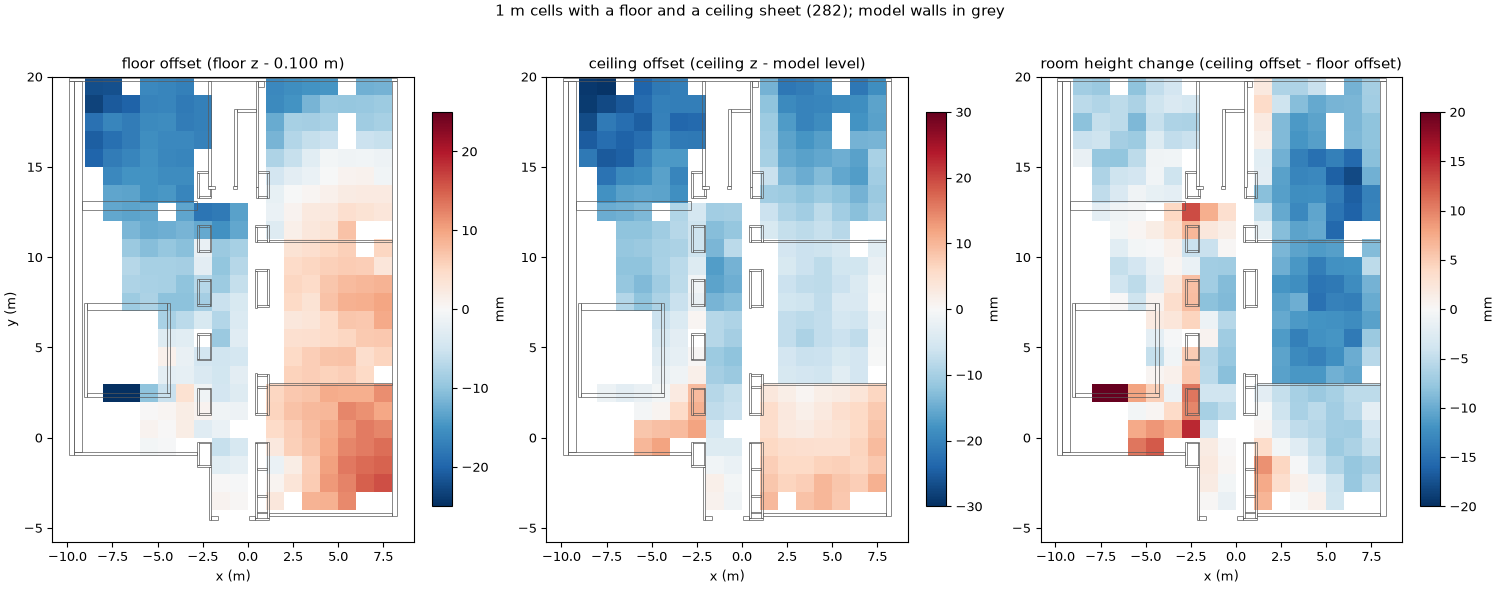

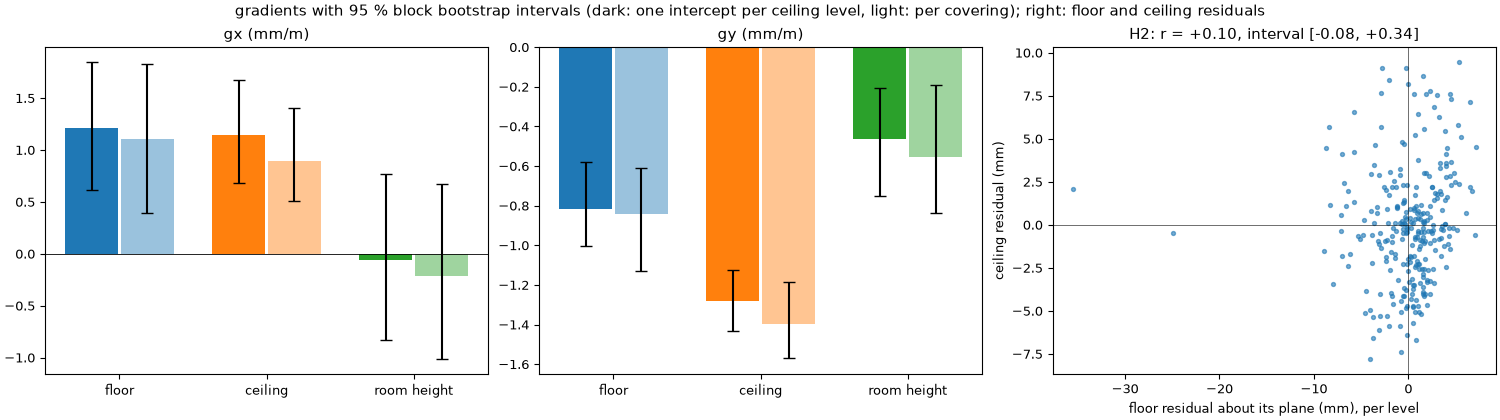

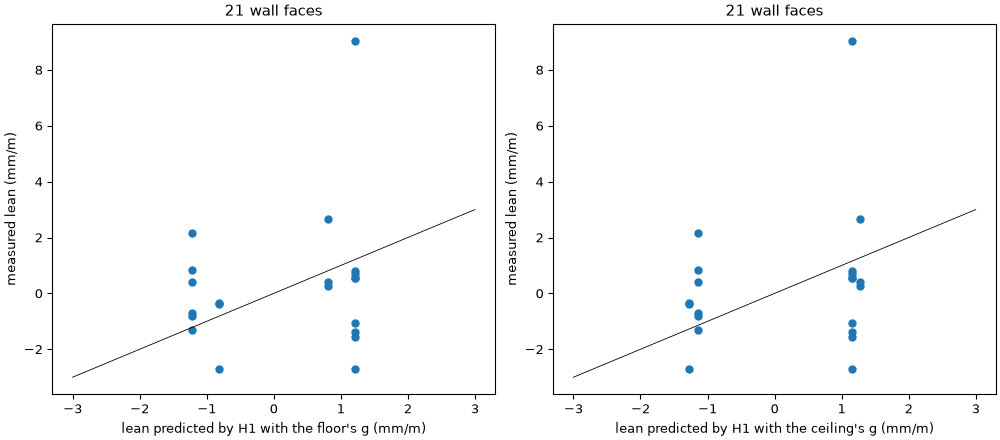

share of the 282 floor cells within 15 mm of the model's floor: as measured 84.0%; with the ceiling-shared plane removed (offset refitted) 99.3%; with the floor's whole plane removed 99.3%  (cell medians, not a verdict)
wrote ../outputs/03d/summary.json; figures 1 s; peak RSS 0.52 GB, total 123 s since section 3


In [8]:
t_fig = time.time()
segments = footprints(walls)


def grid_of(values: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    ix, iy = np.floor(cells.x / CELL).astype(int), np.floor(cells.y / CELL).astype(int)
    grid = np.full((iy.max() - iy.min() + 1, ix.max() - ix.min() + 1), np.nan)
    grid[iy - iy.min(), ix - ix.min()] = values * MM
    return (np.arange(ix.min(), ix.max() + 2) * CELL, np.arange(iy.min(), iy.max() + 2) * CELL, grid)


fig, axes = plt.subplots(1, 3, figsize=(15, 6), constrained_layout=True)
for ax, vals, title in ((axes[0], cells.floor_offset(), "floor offset (floor z - 0.100 m)"), (axes[1], cells.ceiling_offset(), "ceiling offset (ceiling z - model level)"),
                        (axes[2], cells.height_change(), "room height change (ceiling offset - floor offset)")):
    xe, ye, grid = grid_of(vals)
    lim = max(5.0, np.ceil(np.nanpercentile(np.abs(grid), 98) / 5) * 5)
    mesh = ax.pcolormesh(xe, ye, grid, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.add_collection(LineCollection(segments, colors="0.35", linewidths=0.5))
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.set_xlabel("x (m)")
    fig.colorbar(mesh, ax=ax, shrink=0.7, label="mm")
axes[0].set_ylabel("y (m)")
fig.suptitle(f"1 m cells with a floor and a ceiling sheet ({n_cells}); model walls in grey")
fig.savefig(OUT / "cells_map.png")
plt.close(fig)
display(Image(OUT / "cells_map.png"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
for j, (ax, comp) in enumerate(zip(axes[:2], ("gx (mm/m)", "gy (mm/m)"))):
    for k, (by, shade) in enumerate((("level", 1.0), ("room", 0.55))):
        est = [(f.gx if j == 0 else f.gy) * MM for f in fits[by]]
        err = np.array([[est[i] - interval(boots[by][:, 2 * i + j])[0], interval(boots[by][:, 2 * i + j])[1] - est[i]] for i in range(3)]).T
        ax.bar(np.arange(3) + (k - 0.5) * 0.38, est, 0.36, yerr=err, color=[(*c, 1) for c in ((0.12, 0.47, 0.71), (1.0, 0.5, 0.05), (0.17, 0.63, 0.17))] if k == 0 else [(0.12, 0.47, 0.71, 0.45), (1.0, 0.5, 0.05, 0.45), (0.17, 0.63, 0.17, 0.45)],
               capsize=4, label="intercept per level" if k == 0 else "intercept per covering")
    ax.set_xticks(range(3), ["floor", "ceiling", "room height"])
    ax.axhline(0, color="k", lw=0.6)
    ax.set_title(comp)
fig.suptitle("gradients with 95 % block bootstrap intervals (dark: one intercept per ceiling level, light: per covering); right: floor and ceiling residuals")
axes[2].scatter(fl.residuals * MM, ce.residuals * MM, s=8, alpha=0.6)
axes[2].set_xlabel("floor residual about its plane (mm), per level")
axes[2].set_ylabel("ceiling residual (mm)")
axes[2].set_title(f"H2: r = {r_all:+.2f}, interval [{r_ci[0]:+.2f}, {r_ci[1]:+.2f}]")
axes[2].axhline(0, color="k", lw=0.4)
axes[2].axvline(0, color="k", lw=0.4)
fig.savefig(OUT / "gradients.png")
plt.close(fig)
display(Image(OUT / "gradients.png"))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), constrained_layout=True)
for ax, (label, (pa, pb)) in zip(axes, [(k, predictions[k]) for k in ("H1 with the floor's g", "H1 with the ceiling's g")]):
    pred = leans[:, 0] * pa + leans[:, 1] * pb
    ax.scatter(pred, leans[:, 2] * MM, s=25)
    ax.plot([-3, 3], [-3, 3], "k", lw=0.6)
    ax.set_xlabel(f"lean predicted by {label} (mm/m)")
    ax.set_ylabel("measured lean (mm/m)")
    ax.set_title(f"{n_faces} wall faces")
fig.savefig(OUT / "wall_lean.png")
plt.close(fig)
display(Image(OUT / "wall_lean.png"))

# How much of the cell medians' offset do the parts remove? Diagnostic only (cell medians, not counted points, and not a verdict).
off = cells.floor_offset()
tilt_like = off - (ce.gx * cells.x + ce.gy * cells.y)
full = fl.residuals


def share(v: np.ndarray) -> float:
    """Share of the values within TOL of their own median (the offset refitted)."""
    return float(np.mean(np.abs(v - np.median(v)) <= TOL))


share_raw = float(np.mean(np.abs(off) <= TOL))
print(f"share of the {n_cells} floor cells within {TOL * MM:.0f} mm of the model's floor: as measured {share_raw:.1%}; "
      f"with the ceiling-shared plane removed (offset refitted) {share(tilt_like):.1%}; with the floor's whole plane removed {share(full):.1%}  (cell medians, not a verdict)")

def surface_summary(by: str) -> dict[str, dict[str, Any]]:
    return {name: {"gx": fit.gx * MM, "gy": fit.gy * MM, "gx_ci": interval(boots[by][:, 2 * i]), "gy_ci": interval(boots[by][:, 2 * i + 1]), "rms_mm": fit.rms * MM}
            for i, (name, fit) in enumerate(zip(("floor", "ceiling", "height"), fits[by]))}


# Where the room height changes with x or y inside one group of cells: the rows of section 5 whose room-height interval excludes 0 (a floor that slopes while the ceiling does not, or the reverse)
local_floor_only = {label: {"n_cells": row["n_cells"], "height_gx": row["gradient_mm_per_m"][4], "height_gx_ci": row["intervals"][4], "height_gx_excludes_0": not (row["intervals"][4][0] <= 0 <= row["intervals"][4][1]),
                            "height_gy": row["gradient_mm_per_m"][5], "height_gy_ci": row["intervals"][5], "height_gy_excludes_0": not (row["intervals"][5][0] <= 0 <= row["intervals"][5][1])}
                    for label, row in subsets.items() if label.startswith(("level", "covering"))}
summary = {
    "frame": "outputs/03a/frame.json refined_scan_to_model_4x4",
    "floor_z": FLOOR_Z, "ceiling_levels": [float(z) for z in LEVELS], "n_coverings": len(COVERINGS),
    "n_cells": n_cells, "cells_left_out": left_out, "n_boot": N_BOOT, "block_m": BLOCK,
    **surface_summary("level"),  # floor, ceiling, height: one intercept per ceiling level (the planned reading)
    "per_covering": surface_summary("room"),  # the same with one intercept per covering
    "height_predictions_inside_ci": height_inside,
    "left_out_off_level_sheets": {"n": len(off), "per_covering": off_summary},
    "sensitivity_nearest_level_any_covering": {**sensitivity, "note": "not the reading: sheets 5 cm or more from their own covering's level come back, assigned to another covering's level"},
    "sensitivity_readmit_near_matching_level": sensitivity_near,
    "local_floor_only_slopes": local_floor_only,
    "subsets": subsets,
    "residual_correlation": corr["level"], "residual_correlation_per_covering": corr["room"],
    "wall_lean": {"n_faces": n_faces, "a": a_fit, "b": b_fit, "a_ci": interval(lean_boot[:, 0]), "b_ci": interval(lean_boot[:, 1]),
                  "median_abs_lean_mm_per_m": float(np.median(np.abs(leans[:, 2])) * MM), "predictions_inside_ci": within},
    "share_cells_within_tol": {"as_measured": share_raw, "ceiling_plane_removed": share(tilt_like), "floor_plane_removed": share(full)},
    "unit": "gradients in mm/m, offsets in mm",
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2))
print(f"wrote {OUT / 'summary.json'}; figures {time.time() - t_fig:.0f} s; peak RSS {peak_rss_gb():.2f} GB, total {time.time() - t0:.0f} s since section 3")

## Reading

**The numbers (mm per m, one intercept per ceiling level, 95 % block bootstrap intervals; 282 cells of 1 m with a floor and a ceiling sheet).** Floor (+1.21 [+0.61, +1.85], -0.82 [-1.00, -0.58]): the cells reproduce 03a's ramp (+1.22, -0.82). Ceiling (+1.15 [+0.68, +1.68], -1.28 [-1.43, -1.12]). Room height, ceiling minus floor (-0.06 [-0.83, +0.77], -0.46 [-0.75, -0.20]). One intercept per covering instead (each room's suspended ceiling free to sit differently) gives the same picture: floor (+1.11, -0.84), ceiling (+0.90, -1.40), height (-0.21 [-1.01, +0.67], -0.55 [-0.84, -0.19]). Leaving out the two cells with a residual above 15 mm changes the height gradient to (+0.11, -0.42) and (+0.03, -0.43). The fitted ramp is the same in floor and ceiling, which is what a rigid tilt does: the ceiling of the same building, which no floor-only cause can reach, turns the same way by about the same amount (0.099 degrees for the ceiling's gradient, 0.084 degrees for the floor's).

**H3, the floor really slopes: not supported building-wide, but indicated locally in x.** A floor that slopes while the ceiling stays at its levels would make the room height change by minus the floor's gradient, (-1.21, +0.82). The measured building-wide room height gradient is (-0.06 [-0.83, +0.77], -0.46 [-0.75, -0.20]): the x prediction is outside its interval, and in y the measured sign is the opposite of the prediction. The ceiling shares the ramp, so the building-wide part of it is not in the floor alone. Per covering (section 5), two rooms do show a floor-only slope in x whose interval excludes 0: the south-east room (x +1 to +8, y -4 to +3: floor +1.80, ceiling +0.40, room height gx -1.40 [-3.25, -0.22], 46 cells) and the corridor (x -2 to 0: floor +1.76, ceiling +0.25, room height gx -1.51 [-3.27, -0.32], 33 cells). At the 2.80 m level (x >= 0) the room height gx is -0.67 [-1.53, +0.41], which does not exclude 0. These are single rooms with wide intervals: a local floor slope of about 1.5 mm/m in x is indicated there, not established (an as-built ceiling that is not parallel to the floor would look the same).

**H2, drift between the merged setups: not supported.** After removing each surface's plane, the residuals of floor and ceiling are not correlated: r = +0.10, 95 % interval [-0.08, +0.34] (per covering +0.09 [-0.07, +0.28]), against r = +0.74 before the planes are removed (the plane they share). A setup that sat too high would have moved the floor and the ceiling of its patch together and left a positive r. The interval does not exclude a weak shared part (r up to about 0.3), and 4 mm of rms in the floor and 3 mm in the ceiling about their planes are not shared in any visible way: the quadratic part 03a saw in the floor looks like the floor's own unevenness (at the 4 mm level, far from the 15 mm tolerance) rather than a setup drift that the ceiling also carries.

**H1, a rigid tilt: the one candidate left, with a remainder in y.** In x the room height gradient is consistent with zero (-0.06 [-0.83, +0.77]): the whole x ramp is shared by floor and ceiling. In y it is not quite zero (-0.46 [-0.75, -0.20], about 11 mm over the 24 m of the building): the ceiling turns 0.46 mm/m more than the floor, so a rigid tilt explains about 0.8 of the 1.28 mm/m in the ceiling and all of the floor's, and the rest is not explained here (a ceiling that is not parallel to the floor as built, a model level that is not the as-built level, or a small non-rigid part). The per-covering rows (section 5) show that the surfaces are not exactly parallel at the 1 mm/m level inside single rooms: the height gradient in y is -0.93 [-1.70, -0.31] in the south-east room and +0.81 [-0.25, +1.04] in the north-east room, with 46 to 49 cells each, so the global fit averages room-level differences of both signs and the intervals of single rooms are wide. The wall lean agrees with a tilt but is weak evidence: 21 faces qualify, the lean fit is -0.29 nx +1.13 ny mm/m with intervals a [-1.88, +1.04] and b [+0.32, +2.68]; a tilt with the ceiling's gradient predicts (-1.15, +1.28) and with the floor's (-1.21, +0.82), both inside the intervals, and "no lean" (H3) is outside (b excludes 0), so the walls lean in y the way a tilt predicts; in x they cannot tell the two apart. Single real faces are out of plumb by about 0.8 mm/m (median), and the lean fit leaves 2.3 mm/m rms.

**The cells left out, and why the x result depends on the rule that leaves them out.** A sheet counts for the covering over the cell (the covering whose plan box holds the cell, the nearest level if several do) and only if it lies within 5 cm of that covering's level. 46 of the 392 thin ceiling sheets fail that. They are not scattered: 23 lie 10 to 13 cm below the 2.93 m covering of the west rooms (x -10 to -4), 15 lie 34 to 36 cm below the 2.64 m covering of the corridor (x -2 to 0; at 2.29 to 2.30 m, the level of the 2.30 m covering, whose box is narrower than the strip), and 8 lie 24 to 25 cm below the 2.80 m covering at x +2 (matching no level). The sensitivity in section 4 (not the reading) lets them back in, each assigned to the nearest model level of any covering: 303 cells, floor (+1.77, -0.79), ceiling (+0.28 [-0.58, +1.34], -1.23), room height (-1.49 [-3.16, +0.20], -0.44 [-0.71, -0.21]): the ceiling's gx falls from +1.15 to +0.28 and the room height gx rises from -0.06 to -1.49, so the x result **depends on this rule** (the y result does not). A second sensitivity tests the corridor sheets on their own: the main rule, plus the left-out sheets within 5 cm of the level of a covering whose plan box is within 1 m of the cell (a ceiling that runs a little past its modelled box). 19 cells come back (17 at 2.30 m, 2 at 2.80 m; 301 cells), and the x result does not move: floor (+1.23 [+0.67, +1.85], -0.81), ceiling (+1.10 [+0.59, +1.72], -1.24), room height (-0.13 [-0.89, +0.66], -0.43 [-0.69, -0.19]). So the corridor sheets are real 2.30 m ceiling, readmitting them is harmless, and they are not what flips the x result in the any-level run. By elimination that flip comes from the other sheets the any-level run takes in: the 23 that lie 10 to 13 cm below the 2.93 m covering of the west rooms and go to the 2.80 m level (not tested on their own). The covering-over-the-cell rule is the right one for those: a sheet 13 cm below its room's covering is not that covering's surface (it is a lowered ceiling or a bulkhead that the model does not have), and giving it to the 2.80 m level, whose cells lie in the east rooms, shares one intercept between rooms that sit apart and turns the layout (low sheets in the west, normal ones in the east) into an x gradient of the ceiling. The x agreement of floor and ceiling above holds for the sheets that are the surface of a modelled covering; it says nothing about the 46 that are not.

**What the test cannot tell.** A rigid tilt of the scan frame against the model and a real lean of the whole building against the model (whose floor and walls are plumb and level) turn floor, ceiling and walls together; they look the same here. A whole-building point-to-plane ICP on wall and ceiling points was tried while preparing this notebook and dropped (exploratory, not reproduced in this notebook): it took 15 minutes and made the floor worse (85 % within 15 mm before, 49 % after), because differences between the as-built walls and the model confound it. The ceiling levels and the coverings' plan boxes come from the model, and the cells left out for being off-level (above) are a selection that the sensitivity bounds but does not remove.

**How much it matters, in cell medians (diagnostic only, not a verdict).** 84.0 % of the 282 floor cells are within 15 mm of the model's floor as measured. With the plane of the ceiling's gradient removed (the part the floor shares with the ceiling, offset refitted on these same cells) 99.3 % are, the same as with the floor's own plane removed (99.3 %). This is a share of 282 cell medians, fitted on the cells it scores; it is not comparable with the 84 % of counted points in 03a and is not a prediction for any correction.

## Conclusion

The ramp of the scan floor is, to the precision of these data, **mostly a tilt of about 0.1 degrees shared by floor and ceiling (+1.2 mm/m in x, -0.8 to -1.3 mm/m in y)**, and weakly by the walls. The candidates are ruled down to **a shared tilt plus an unexplained remainder in y**:

- **H1's own prediction fails in y.** A rigid tilt predicts a room height gradient of 0; in x it is -0.06 [-0.83, +0.77], but in y it is -0.46 [-0.75, -0.20] (the ceiling turns 0.46 mm/m more than the floor, about 11 mm over the building). That remainder is not explained by any of the three hypotheses.
- **H3 (the floor really slopes) is not supported building-wide, under the covering-over-the-cell rule.** The ceiling carries the same ramp. The x result depends on that rule: with the 23 west sheets (10 to 13 cm below the 2.93 m covering) assigned to the 2.80 m level instead, the room height gx is -1.49 [-3.16, +0.20], which holds H3's prediction (-1.21). Locally, a floor-only slope of about 1.5 mm/m in x is indicated in two rooms (the south-east room and the corridor: room height gx -1.40 [-3.25, -0.22] and -1.51 [-3.27, -0.32]) but not established, since these are single rooms with wide intervals.
- **H2 (setup drift) is not supported:** the floor and ceiling residuals about their planes are uncorrelated (r = +0.10 [-0.08, +0.34]).
- Whether the shared tilt belongs to the frame (a registration matter) or to the building (then the model is off level, not the floor) is open: the two look the same here.

## Decision

The floor slab's verdict **does not change in Phase 0.5**: no verdict rule or parameter is changed and nothing was tuned on the gate's samples (owner decision 2026-11-04). Its "not confirmed" is judged against the model's flat floor at the frame 03a has. What Phase 2 (issue #33) should consider, given this cause:

- the 16 % of the slab outside tolerance is **mostly a tilt shared by floor and ceiling**, whether of the frame (a registration matter) or of the building (then the model is off level, not the floor). In cell medians (diagnostic only; the 84 % of points of 03a is not comparable) that shared tilt accounts for nearly all the cells outside 15 mm. A whole-building level and tilt step taken from planes that do not depend on the element being judged (floor and ceiling planes of the building) is the thing to consider; it must be validated off the gate (on rooms and buildings that are not the gate's), it cannot tell a frame tilt from a building that is out of plumb, and an estimate from the ceiling needs the ceilings to exist in the scan;
- whichever way, a slab judged against a flat model floor over a whole building at 15 mm is sensitive to tilts of 0.1 degrees (15 mm at 10 m): the rule for large horizontal elements (judge against a locally fitted plane, or only after a global level step) is a Phase 2 design choice, not decided here;
- the floor's own unevenness (4 mm rms about its plane, not visibly shared with the ceiling) is small against the tolerance, but it means a flat model floor will not match the scan floor exactly;
- the rule must leave room for **local real floor slopes** (the two rooms above, if confirmed): a global level step removes the building-wide tilt and would leave them, so a slab judged after such a step can still be out of tolerance in those rooms for a true reason, and the rule must not hide that;
- if the floor did slope in the building, "not confirmed" would be the honest verdict for the slab; the data here do not show that.